In [88]:
import sys
sys.path.append("..")

from src.data_cleaning import load_data

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

import numpy
import pandas as pd

import torch
from torch import nn 
from torch.utils.data import TensorDataset, DataLoader
from torch import cuda

import copy

import matplotlib.pyplot as plt

In [69]:
RANDOM_STATE = 40

X, y = load_data()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

- MLP

In [70]:
BATCH_SIZE = 16
DROPOUT = 0.3
LEARNING_RATE = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-3
EPOCHS = 2000


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


In [71]:
Xt_train = torch.tensor(X_train, dtype=torch.float32, device=device)
yt_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)

Xt_val = torch.tensor(X_val, dtype=torch.float32, device=device)
yt_val = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)

Xt_test = torch.tensor(X_test, dtype=torch.float32, device=device)
yt_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)


in_features = Xt_train.shape[1]
out_features = len(torch.unique(yt_train))

train_dataset = TensorDataset(Xt_train, yt_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [72]:
class MLP(nn.Module) :
    
    def __init__(self):
        super().__init__()
        self.layer1 = nn.Linear(in_features, 16, device=device)
        self.layer2 = nn.Linear(16, 16, device=device)
        self.layer3 = nn.Linear(16, out_features, device=device)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=DROPOUT)

    def forward(self, x):
        x = self.relu(self.layer1(x))
        x = self.dropout(x)
        x = self.relu(self.layer2(x))
        x = self.dropout(x)
        x = self.layer3(x)
        return x

In [73]:
mlp_model = MLP()
optimizer = torch.optim.SGD(params=mlp_model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss()

def accuracy(yt_pred, yt_true):
    return (yt_pred == yt_true).float().mean()

In [74]:
train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_val_accuracy = 0.0
best_weights = None
best_epoch = 0

for epoch in range(1, EPOCHS+1):

    mlp_model.train()
    mean_train_loss = 0
    mean_train_acc = 0
    mean_test_loss = 0
    mean_test_acc = 0
    
    for Xt_batch, yt_batch in train_loader :

        yt_pred = mlp_model(Xt_batch)

        train_loss = criterion(yt_pred, yt_batch)
        mean_train_loss += train_loss.item() * Xt_batch.shape[0]/Xt_train.shape[0]

        yt_pred_class = torch.argmax(yt_pred, dim=1)
        train_acc = accuracy(yt_pred_class, yt_batch)
        mean_train_acc += train_acc.item() * Xt_batch.shape[0]/Xt_train.shape[0]


        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()


    mlp_model.eval()

    with torch.no_grad() :
        
        yt_pred = mlp_model(Xt_val)

        val_loss = criterion(yt_pred, yt_val).item()

        yt_pred_class = torch.argmax(yt_pred, dim=1)
        val_acc = accuracy(yt_pred_class, yt_val).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_val_accuracy = val_acc
            best_weights = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch

    
    if epoch%100 == 0:

        train_losses.append(mean_train_loss)
        val_losses.append(val_loss)
        train_accuracies.append(mean_train_acc)
        val_accuracies.append(val_acc)

        print(f"Epoch: {epoch}")
        print(f"Train loss: {mean_train_loss:.4f} | Train accuracy: {mean_train_acc:.2%}")
        print(f"Val loss: {val_loss:.4f} | Val accuracy: {val_acc:.2%}")
        print("")


mlp_model.load_state_dict(best_weights)
print("")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy at best epoch: {best_val_accuracy:.2%}")

Epoch: 100
Train loss: 0.6566 | Train accuracy: 68.12%
Val loss: 0.6452 | Val accuracy: 71.11%

Epoch: 200
Train loss: 0.6169 | Train accuracy: 71.01%
Val loss: 0.6012 | Val accuracy: 80.00%

Epoch: 300
Train loss: 0.5694 | Train accuracy: 76.81%
Val loss: 0.5418 | Val accuracy: 80.00%

Epoch: 400
Train loss: 0.5463 | Train accuracy: 75.85%
Val loss: 0.4818 | Val accuracy: 80.00%

Epoch: 500
Train loss: 0.4809 | Train accuracy: 79.23%
Val loss: 0.4334 | Val accuracy: 82.22%

Epoch: 600
Train loss: 0.4703 | Train accuracy: 81.16%
Val loss: 0.3983 | Val accuracy: 86.67%

Epoch: 700
Train loss: 0.4238 | Train accuracy: 80.19%
Val loss: 0.3757 | Val accuracy: 86.67%

Epoch: 800
Train loss: 0.4507 | Train accuracy: 81.64%
Val loss: 0.3610 | Val accuracy: 86.67%

Epoch: 900
Train loss: 0.4108 | Train accuracy: 84.06%
Val loss: 0.3511 | Val accuracy: 86.67%

Epoch: 1000
Train loss: 0.4379 | Train accuracy: 83.09%
Val loss: 0.3434 | Val accuracy: 86.67%

Epoch: 1100
Train loss: 0.4233 | Train 

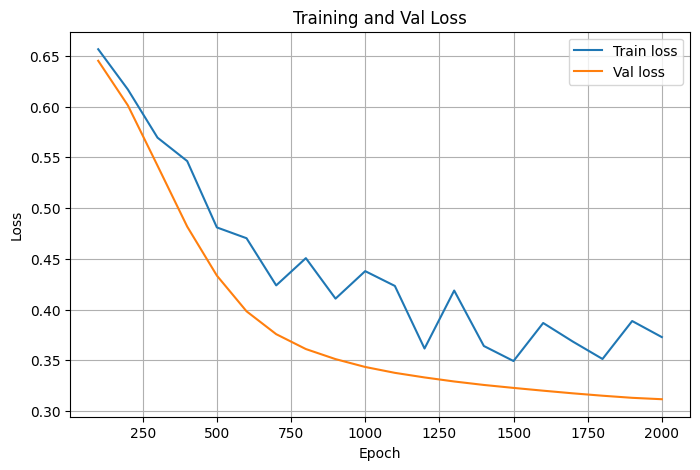

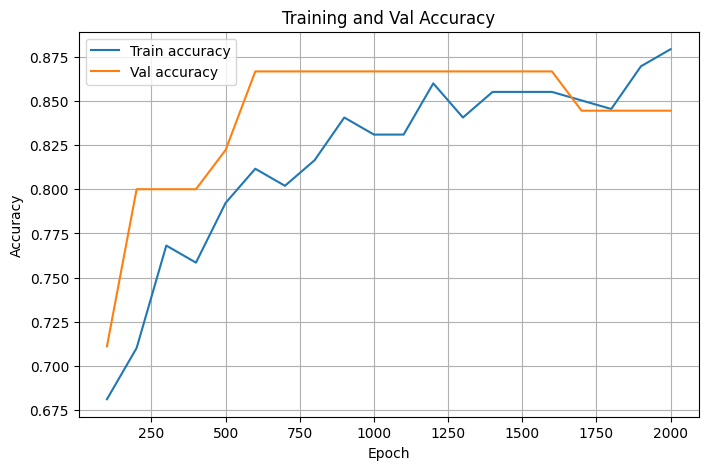

In [75]:
import matplotlib.pyplot as plt

epochs = range(100, EPOCHS + 1, 100)

# Graphe 1 : Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Val Loss")
plt.legend()
plt.grid(True)
plt.show()

# Graphe 2 : Accuracy
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label="Train accuracy")
plt.plot(epochs, val_accuracies, label="Val accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Val Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [76]:
mlp_model.eval()

with torch.no_grad():
    yt_pred = mlp_model(Xt_test)

    test_loss = criterion(yt_pred, yt_test).item()
    yt_pred_class = torch.argmax(yt_pred, dim=1)

    y_true_mlp = yt_test.cpu().numpy()
    y_pred_mlp = yt_pred_class.cpu().numpy()

test_acc = accuracy(yt_pred_class, yt_test).item()
test_precision = precision_score(y_true_mlp, y_pred_mlp, zero_division=0)
test_recall = recall_score(y_true_mlp, y_pred_mlp, zero_division=0)
test_f1 = f1_score(y_true_mlp, y_pred_mlp, zero_division=0)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Test precision: {test_precision:.2%}")
print(f"Test recall: {test_recall:.2%}")
print(f"Test F1-score: {test_f1:.2%}")

Test loss: 0.3295
Test accuracy: 86.67%
Test precision: 89.47%
Test recall: 80.95%
Test F1-score: 85.00%


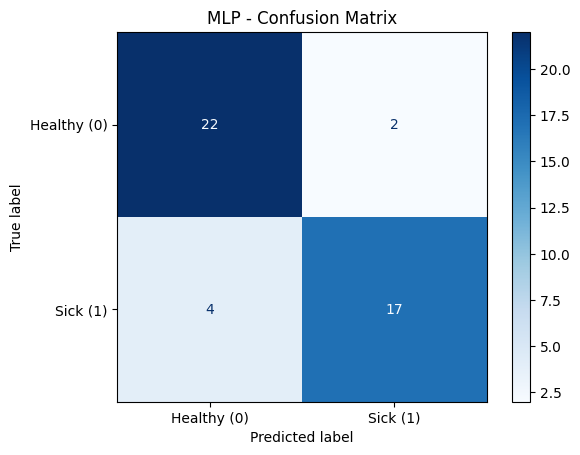

In [77]:
ConfusionMatrixDisplay.from_predictions(
    yt_test.cpu().numpy(),
    yt_pred_class.cpu().numpy(),
    display_labels=["Healthy (0)", "Sick (1)"],
    cmap="Blues"
)

plt.title("MLP - Confusion Matrix")
plt.show()

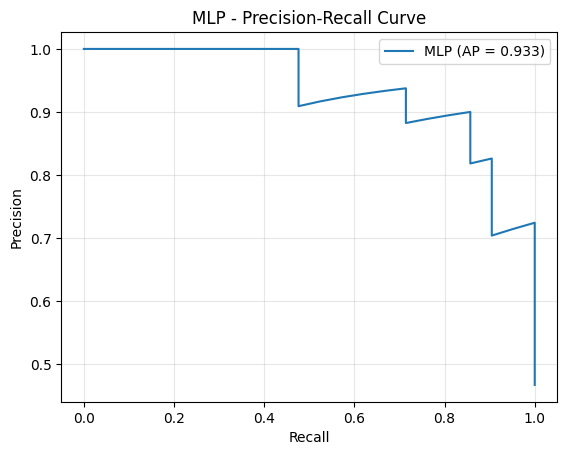

In [84]:
y_true_mlp = yt_test.cpu().numpy()

with torch.no_grad():
    y_proba_mlp = torch.softmax(mlp_model(Xt_test), dim=1)[:, 1].cpu().numpy()

precision_mlp_curve, recall_mlp_curve, _ = precision_recall_curve(
    y_true_mlp, y_proba_mlp
)

ap_mlp = average_precision_score(y_true_mlp, y_proba_mlp)

plt.plot(
    recall_mlp_curve,
    precision_mlp_curve,
    label=f"MLP (AP = {ap_mlp:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MLP - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Logistic Regression

In [78]:
model_reg = sklearn.linear_model.LogisticRegressionCV(
    max_iter=1000,
    random_state=RANDOM_STATE
)

model_reg.fit(X_train, y_train)

y_pred_logreg = model_reg.predict(X_test)
y_proba_logreg = model_reg.predict_proba(X_test)

loss_logreg = sklearn.metrics.log_loss(y_test, y_proba_logreg)
acc_logreg = sklearn.metrics.accuracy_score(y_test, y_pred_logreg)
precision_logreg = sklearn.metrics.precision_score(y_test, y_pred_logreg, zero_division=0)
recall_logreg = sklearn.metrics.recall_score(y_test, y_pred_logreg, zero_division=0)
f1_logreg = sklearn.metrics.f1_score(y_test, y_pred_logreg, zero_division=0)

print(f"Test loss: {loss_logreg:.4f}")
print(f"Test accuracy: {acc_logreg:.2%}")
print(f"Test precision: {precision_logreg:.2%}")
print(f"Test recall: {recall_logreg:.2%}")
print(f"Test F1-score: {f1_logreg:.2%}")

c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2092: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2137: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
c:\miniconda\Lib\site-packages\sklearn\linear_model\_logistic.py:2150: FutureWarning: The fitted attributes of LogisticRegressionCV will be simplified in scikit-learn 1.10 to remove redundancy. Set`use_legacy_attributes=False` to enable the new behavior now, or set 

Test loss: 0.4783
Test accuracy: 84.44%
Test precision: 93.75%
Test recall: 71.43%
Test F1-score: 81.08%


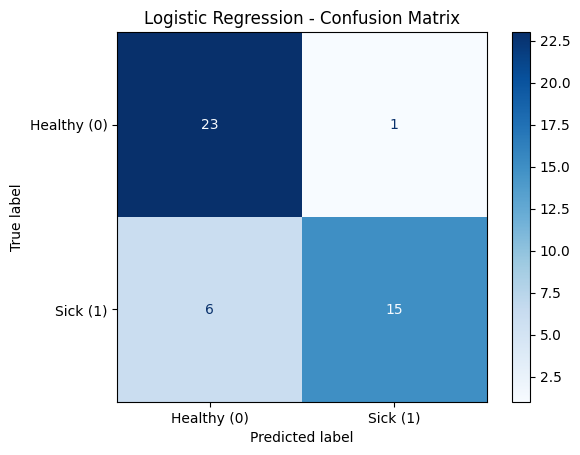

In [79]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_logreg,
    display_labels=["Healthy (0)", "Sick (1)"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

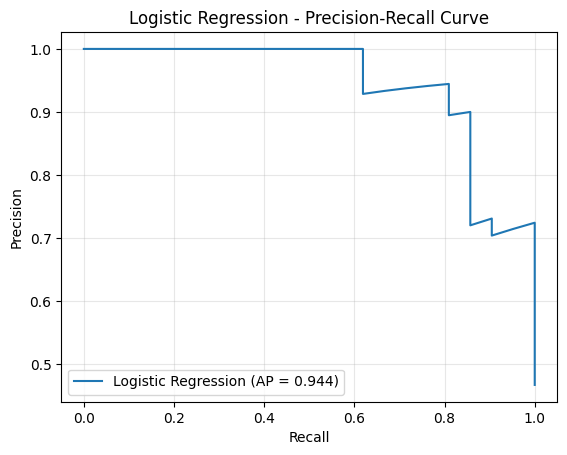

In [85]:
precision_logreg_curve, recall_logreg_curve, _ = precision_recall_curve(
    y_test, y_proba_logreg[:, 1]
)

ap_logreg = average_precision_score(
    y_test, y_proba_logreg[:, 1]
)

plt.plot(
    recall_logreg_curve,
    precision_logreg_curve,
    label=f"Logistic Regression (AP = {ap_logreg:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Logistic Regression - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Random Forest

In [80]:
model = RandomForestClassifier(random_state=RANDOM_STATE)

params = {
    "n_estimators": [10, 25, 50, 100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 3, 5]
}

grid = GridSearchCV(
    model,
    params,
    cv=5,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
print("")

best_model = grid.best_estimator_

y_pred_rf = best_model.predict(X_test)
y_proba_rf = best_model.predict_proba(X_test)

loss_rf = sklearn.metrics.log_loss(y_test, y_proba_rf)
acc_rf = sklearn.metrics.accuracy_score(y_test, y_pred_rf)
precision_rf = sklearn.metrics.precision_score(y_test, y_pred_rf, zero_division=0)
recall_rf = sklearn.metrics.recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = sklearn.metrics.f1_score(y_test, y_pred_rf, zero_division=0)

print(f"Test loss: {loss_rf:.4f}")
print(f"Test accuracy: {acc_rf:.2%}")
print(f"Test precision: {precision_rf:.2%}")
print(f"Test recall: {recall_rf:.2%}")
print(f"Test F1-score: {f1_rf:.2%}")

{'max_depth': None, 'min_samples_split': 2, 'n_estimators': 100}
0.8545876887340302

Test loss: 0.3738
Test accuracy: 86.67%
Test precision: 89.47%
Test recall: 80.95%
Test F1-score: 85.00%


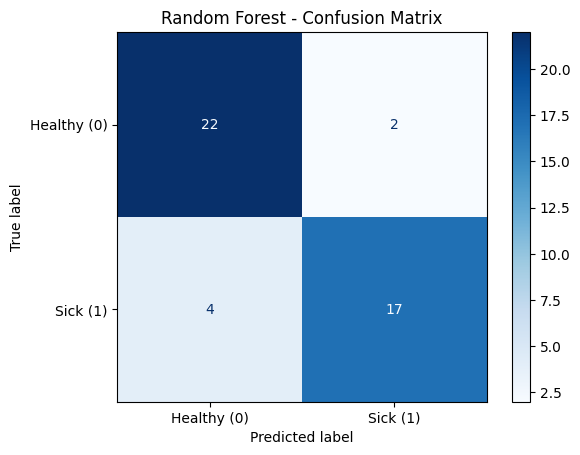

In [81]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Healthy (0)", "Sick (1)"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

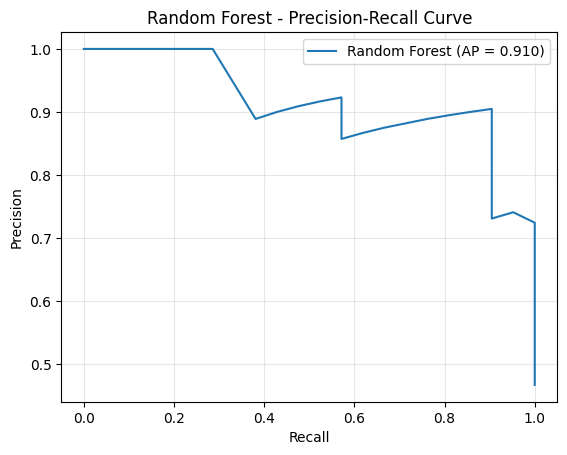

In [86]:
precision_rf_curve, recall_rf_curve, _ = precision_recall_curve(
    y_test, y_proba_rf[:, 1]
)

ap_rf = average_precision_score(
    y_test, y_proba_rf[:, 1]
)

plt.plot(
    recall_rf_curve,
    precision_rf_curve,
    label=f"Random Forest (AP = {ap_rf:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Random Forest - Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


- Overview

In [89]:
results = pd.DataFrame({
    "Model": ["MLP", "Logistic Regression", "Random Forest"],
    "Loss": [test_loss, loss_logreg, loss_rf],
    "Accuracy": [test_acc, acc_logreg, acc_rf],
    "Precision": [test_precision, precision_logreg, precision_rf],
    "Recall": [test_recall, recall_logreg, recall_rf],
    "F1-score": [test_f1, f1_logreg, f1_rf],
    "Average Precision": [ap_mlp, ap_logreg, ap_rf]
})

results = results.set_index("Model")
display(results.round(4))

,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,
MLP,0.3295,0.8667,0.8947,0.8095,0.8500,0.9327
Logistic Regression,0.4783,0.8444,0.9375,0.7143,0.8108,0.9441
Random Forest,0.3738,0.8667,0.8947,0.8095,0.8500,0.9100


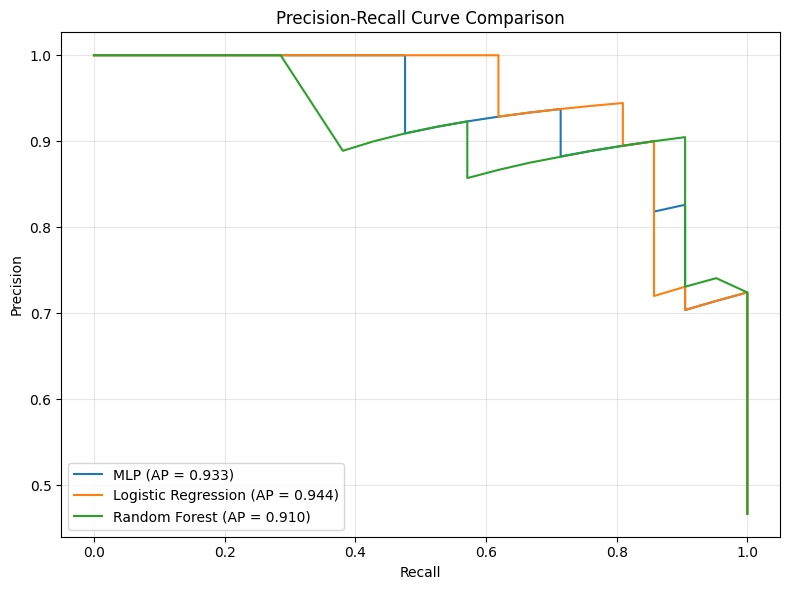

In [91]:
plt.figure(figsize=(8, 6))

plt.plot(
    recall_mlp_curve,
    precision_mlp_curve,
    label=f"MLP (AP = {ap_mlp:.3f})"
)

plt.plot(
    recall_logreg_curve,
    precision_logreg_curve,
    label=f"Logistic Regression (AP = {ap_logreg:.3f})"
)

plt.plot(
    recall_rf_curve,
    precision_rf_curve,
    label=f"Random Forest (AP = {ap_rf:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()